# Non-Parametric Statistical Analysis of French Education Reform

---
Cyprien Loric - M1 IMDS - Université de Haute-Alsace

## I - Libraries and data loading

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set(style="whitegrid")
np.random.seed(42)

In [2]:
df = pd.read_csv("data/fr-en-indicateurs-de-resultat-des-lycees-gt_v2.csv", sep=";")

In [3]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 32485 entries, 0 to 32484
Data columns (total 88 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Année                                               32485 non-null  int64  
 1   UAI                                                 32485 non-null  str    
 2   Etablissement                                       32485 non-null  str    
 3   Secteur                                             32485 non-null  str    
 4   Code commune                                        32485 non-null  str    
 5   Commune                                             32485 non-null  str    
 6   Code departement                                    32485 non-null  str    
 7   Département                                         32485 non-null  str    
 8   Académie                                            32485 non-null  str    
 9   Code r

,Année,UAI,Etablissement,Secteur,Code commune,Commune,Code departement,Département,Académie,Code région,...,Valeur ajoutée du taux de mentions - S2TMD,Valeur ajoutée du taux de mentions - STHR,Nombre de mentions TB avec félicitations - G,Nombre de mentions TB sans félicitations - G,Nombre de mentions B - G,Nombre de mentions AB - G,Nombre de mentions TB avec félicitations - T,Nombre de mentions TB sans félicitations - T,Nombre de mentions B - T,Nombre de mentions AB - T
0,2025,0511135G,LYCEE NOTRE-DAME ST VICTOR,privé sous contrat,51230,EPERNAY,51,MARNE,REIMS,44,...,NaN,NaN,NaN,10.0,20.0,38.0,NaN,NaN,NaN,NaN
1,2025,0511145T,LYCEE ST MICHEL (GENERAL ET TECHNO.),privé sous contrat,51454,REIMS,51,MARNE,REIMS,44,...,NaN,NaN,NaN,3.0,18.0,19.0,NaN,1.0,4.0,17.0
2,2025,0530004S,LYCEE VICTOR HUGO,public,53062,CHATEAU GONTIER SUR MAYENNE,53,MAYENNE,NANTES,52,...,NaN,NaN,NaN,11.0,43.0,49.0,NaN,1.0,5.0,11.0
3,2025,0530010Y,LYCEE AMBROISE PARE,public,53130,LAVAL,53,MAYENNE,NANTES,52,...,NaN,NaN,2.0,21.0,58.0,81.0,NaN,NaN,7.0,23.0
4,2025,0530016E,LYCEE LAVOISIER,public,53147,MAYENNE,53,MAYENNE,NANTES,52,...,NaN,NaN,NaN,12.0,33.0,47.0,NaN,NaN,2.0,10.0


In [4]:
print(f"années disponibles : {df['Année'].unique()}\n")
print(f"secteurs : {df['Secteur'].unique()}")

années disponibles : [2025 2020 2021 2019 2017 2018 2022 2012 2016 2023 2024 2013 2014 2015]

secteurs : <StringArray>
['privé sous contrat', 'public']
Length: 2, dtype: str


In [5]:
# on travaille sur l'année 2025 pour les tests non appariés
df_25 = df[df["Année"] == 2025]
print(f"{df_25.shape[0]} lycées en 2025")
missing = df_25.isna().sum().sort_values(ascending=False)
print(missing)


2346 lycées en 2025
Présents - S                               2346
Présents - ES                              2346
Présents - L                               2346
Valeur ajoutée du taux de réussite - ES    2346
Valeur ajoutée du taux de réussite - L     2346
                                           ... 
Secteur                                       0
Code commune                                  0
Commune                                       0
Taux d'accès terminale-bac                    0
Taux d'accès 1ere-bac                         0
Length: 88, dtype: int64


## II - Descriptive statistics (2025)

In [6]:
# on renomme les colonnes pour alléger l'écriture
reussite = "Valeur ajoutée du taux de réussite - Toutes séries"
mention  = "Valeur ajoutée du taux de mentions - Toutes séries"
effectif = "Présents - Toutes séries"

for nom, col in [("VA réussite", reussite), ("VA mention", mention), ("Effectif", effectif)]:
    v = df_25[col].dropna()
    print(nom, ": n =", len(v), 
          " médiane =", round(v.median(), 2),
          " moyenne =", round(v.mean(), 2),
          " écart-type =", round(v.std(), 2),
          " min =", round(v.min(), 2),
          " max =", round(v.max(), 2))

n_pub  = len(df_25[df_25["Secteur"] == "public"])
n_priv = len(df_25[df_25["Secteur"] == "privé sous contrat"])
total  = n_pub + n_priv
print(f"public : {n_pub} ({round(n_pub / total * 100, 1)}%)")
print(f"privé  : {n_priv} ({round(n_priv / total * 100, 1)}%)")
print(f"total  : {total} lycées")

VA réussite : n = 2207  médiane = 0.0  moyenne = -0.21  écart-type = 2.66  min = -16.0  max = 36.0
VA mention : n = 2207  médiane = 0.0  moyenne = -0.22  écart-type = 6.59  min = -39.0  max = 28.0
Effectif : n = 2346  médiane = 201.5  moyenne = 217.77  écart-type = 129.35  min = 20  max = 885
public : 1562 (66.6%)
privé  : 784 (33.4%)
total  : 2346 lycées


## III - Justification du choix du test

### III.1 Histogram of the data vs normal distribution

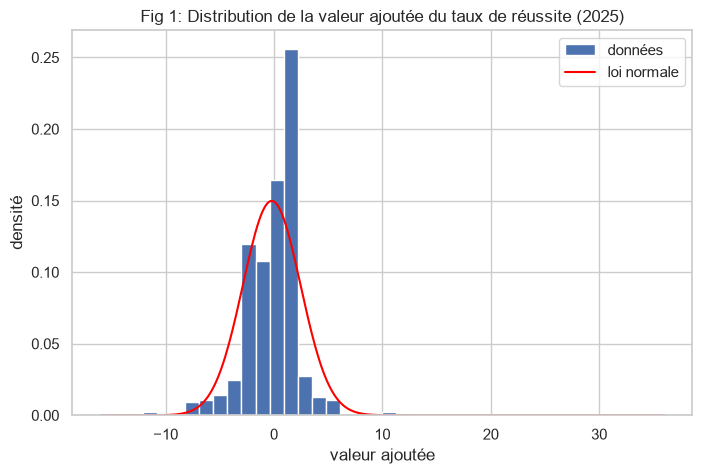

In [7]:
va = df_25[reussite].dropna()

x = np.linspace(va.min(), va.max(), 300)
densite_normale = stats.norm.pdf(x, va.mean(), va.std())

plt.figure(figsize=(8, 5))
plt.hist(va, bins=40, density=True, label="données")
plt.plot(x, densite_normale, color="red", label="loi normale")
plt.xlabel("valeur ajoutée")
plt.ylabel("densité")
plt.title("Fig 1: Distribution de la valeur ajoutée du taux de réussite (2025)")
plt.legend()
plt.show()

### III.2 Separation of small / large high schools (median by sizes)

In [8]:
mediane_eff = df_25[effectif].median()

petits = df_25[df_25[effectif] <= mediane_eff]
grands = df_25[df_25[effectif] >  mediane_eff]

va_petits = petits[reussite].dropna()
va_grands = grands[reussite].dropna()

print("médiane des effectifs :", mediane_eff)
print(f"nbr petits lycées = {len(va_petits)}")
print(f"nbr grands lycées = {len(va_grands)}")
print(f"total = {len(va_petits) + len(va_grands)}")

médiane des effectifs : 201.5
nbr petits lycées = 1042
nbr grands lycées = 1165
total = 2207


### III.3 Chi-squared goodness-of-fit test for normality

In [9]:
# on découpe en 8 classes équiprobables sous la normale estimée
for nom, groupe in [("petits lycées", va_petits), ("grands lycées", va_grands)]:
    mu = groupe.mean()
    sigma = groupe.std()

    bornes = [-np.inf]
    for i in range(1, 8):
        bornes.append(stats.norm.ppf(i / 8, mu, sigma))
    bornes.append(np.inf)

    effectifs_obs, _ = np.histogram(groupe, bins=bornes)
    effectif_theo = len(groupe) / 8
    stat = sum((o - effectif_theo) ** 2 / effectif_theo for o in effectifs_obs)

    # 5 ddl = 8 classes - 1 - 2 paramètres estimés (mu et sigma)
    p = 1 - stats.chi2.cdf(stat, 5)
    print(f"{nom}: chi2 = {round(stat, 2)}, p = {p:.2e}")

petits lycées: chi2 = 325.48, p = 0.00e+00
grands lycées: chi2 = 524.76, p = 0.00e+00


### III.4 Skewness of the two distributions

In [10]:
print(f"asymétrie petits lycées : {round(va_petits.skew(), 2)}")
print(f"asymétrie grands lycées : {round(va_grands.skew(), 2)}")

asymétrie petits lycées : 1.4
asymétrie grands lycées : -0.57


## IV. Question 1: Mann-Whitney (Wilcoxon rank-sum)
---
Does the size of a high school influence its value-added score?

### IV.1 Mann-Whitney test

In [11]:
W, p = stats.mannwhitneyu(va_petits, va_grands, alternative="two-sided")

print(f"petits lycées : médiane = {round(va_petits.median(), 2)}")
print(f"grands lycées : médiane = {round(va_grands.median(), 2)}")
print(f"W = {round(W)}, p = {round(p, 4)}")
if p < 0.05:
    print("différence significative")
else:
    print("différence non significative")

# ampleur et sens de la différence (Cliff's delta, entre -1 et 1)
cliff = 2 * W / (len(va_petits) * len(va_grands)) - 1
print(f"Cliff's delta = {round(cliff, 2)}")

petits lycées : médiane = 1.0
grands lycées : médiane = 0.0
W = 766554, p = 0.0
différence significative
Cliff's delta = 0.26


### IV.2 Boxplot: small vs large high schools

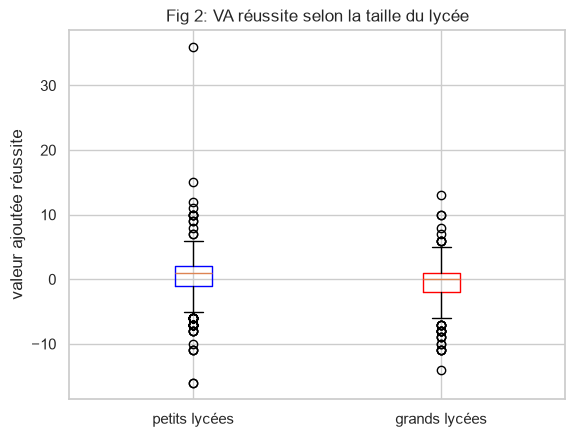

In [12]:
boite = plt.boxplot([va_petits, va_grands], tick_labels=["petits lycées", "grands lycées"])
boite["boxes"][0].set(color="blue")
boite["boxes"][1].set(color="red")
plt.ylabel("valeur ajoutée réussite")
plt.title("Fig 2: VA réussite selon la taille du lycée")
plt.show()

### IV.3 Sensitivity analysis on the cutoff threshold

In [13]:
# on vérifie que la conclusion ne dépend pas du seuil choisi
print("seuil   n petits   n grands   p-value   conclusion   Cliff's delta")
for pct in [30, 40, 50, 60, 70]:
    seuil = df_25[effectif].quantile(pct / 100)
    vp = df_25[df_25[effectif] <= seuil][reussite].dropna()
    vg = df_25[df_25[effectif] >  seuil][reussite].dropna()

    W, p = stats.mannwhitneyu(vp, vg, alternative="two-sided")
    cliff = 2 * W / (len(vp) * len(vg)) - 1

    if p < 0.05:
        conclusion = "significatif"
    else:
        conclusion = "non significatif"
    print(f"{pct}%       {len(vp)}       {len(vg)}       {round(p, 4)}    {conclusion}       {round(cliff, 2)}")

seuil   n petits   n grands   p-value   conclusion   Cliff's delta
30%       578       1629       0.0    significatif       0.29
40%       814       1393       0.0    significatif       0.28
50%       1042       1165       0.0    significatif       0.26
60%       1276       931       0.0    significatif       0.26
70%       1511       696       0.0    significatif       0.26


## V - Question 2: Wilcoxon signed-rank (paired test)
---
Did the Blanquer reform change the value-added score?

### V.1 Construction of paired data

In [14]:
chatel   = df[df["Année"].isin([2015, 2016, 2017, 2018, 2019])]
blanquer = df[df["Année"].isin([2022, 2023, 2024, 2025])]

# VA moyenne de chaque lycée sur chaque période
moy_chatel = chatel.groupby("UAI").agg(
    reussite_c=(reussite, "mean"),
    mention_c =(mention,  "mean"),
    secteur   =("Secteur", "first"),
)
moy_blanquer = blanquer.groupby("UAI").agg(
    reussite_b=(reussite, "mean"),
    mention_b =(mention,  "mean"),
)

# on ne garde que les lycées présents sur les deux périodes
apparies = moy_chatel.join(moy_blanquer).dropna()
print(f"lycées appariés : {len(apparies)}")

lycées appariés : 2284


### V.2 Differences and symmetry check

In [15]:
diff_reussite = apparies["reussite_b"] - apparies["reussite_c"]
diff_mention  = apparies["mention_b"]  - apparies["mention_c"]

print(f"VA réussite : améliorés {len(diff_reussite[diff_reussite > 0])}, dégradés {len(diff_reussite[diff_reussite < 0])}")
print(f"VA mention  : améliorés {len(diff_mention[diff_mention > 0])}, dégradés {len(diff_mention[diff_mention < 0])}")

print(f"asymétrie diff réussite : {round(diff_reussite.skew(), 2)}")
print(f"asymétrie diff mention  : {round(diff_mention.skew(), 2)}")

VA réussite : améliorés 1087, dégradés 1165
VA mention  : améliorés 1079, dégradés 1191
asymétrie diff réussite : 0.39
asymétrie diff mention  : -0.3


### V.3 Wilcoxon signed-rank test on the success-rate value-added

In [16]:
# on enlève les différences nulles (ex aequo)
diff_r = diff_reussite[diff_reussite != 0]
T_r, p_r = stats.wilcoxon(diff_r, alternative="two-sided")

print(f"VA réussite : n = {len(diff_r)}")
print(f"médiane des différences = {round(diff_reussite.median(), 2)}")
print(f"T+ = {round(T_r)}, p = {round(p_r, 4)}")

if p_r < 0.05:
    print("différence significative")
else:
    print("différence non significative")

VA réussite : n = 2252
médiane des différences = -0.1
T+ = 1252783, p = 0.6119
différence non significative


### V.4 Wilcoxon signed-rank test on the honors-rate value-added

In [17]:
diff_m = diff_mention[diff_mention != 0]
T_m, p_m = stats.wilcoxon(diff_m, alternative="two-sided")

print(f"VA mention : n ={len(diff_m)}")
print(f"médiane des différences = {round(diff_mention.median(), 2)}")
print(f"T+ ={round(T_m)}, p ={round(p_m, 4)}")

if p_m < 0.05:
    print("différence significative")
else:
    print("différence non significative")

VA mention : n =2270
médiane des différences = -0.33
T+ =1187298, p =0.0012
différence significative


### V.5 Effect size

In [18]:
# r de rang, à partir de la loi de T+ sous H0
for nom, T, n in [("VA réussite", T_r, len(diff_r)), ("VA mention", T_m, len(diff_m))]:
    esperance = n * (n + 1) / 4
    ecart_type = np.sqrt(n * (n + 1) * (2 * n + 1) / 24)
    Z = abs(T - esperance) / ecart_type
    r = Z / np.sqrt(n)
    print(f"{nom}: Z = {round(Z, 2)}, r = {round(r, 3)}")

VA réussite: Z = 0.51, r = 0.011
VA mention: Z = 3.25, r = 0.068


### V.6 Analysis by sector (honors-rate value-added)

In [19]:
print("secteur   n           médiane diff       p-value     conclusion")
for nom, secteur in [("public", "public"), ("privé", "privé sous contrat")]:
    d = diff_mention[apparies["secteur"] == secteur]
    d_nz = d[d != 0]
    T, p = stats.wilcoxon(d_nz, alternative="two-sided")
    conclusion = "significatif" if p < 0.05 else "non significatif"
    print(f"{nom}:  n = {len(d)},    médiane = {round(d.median(), 2)},   p = {round(p, 4)},   {conclusion}")

secteur   n           médiane diff       p-value     conclusion
public:  n = 1523,    médiane = 0.33,   p = 0.3873,   non significatif
privé:  n = 761,    médiane = -1.58,   p = 0.0,   significatif


### V.7 Boxplot of honors-rate value-added before / after the reform, by sector

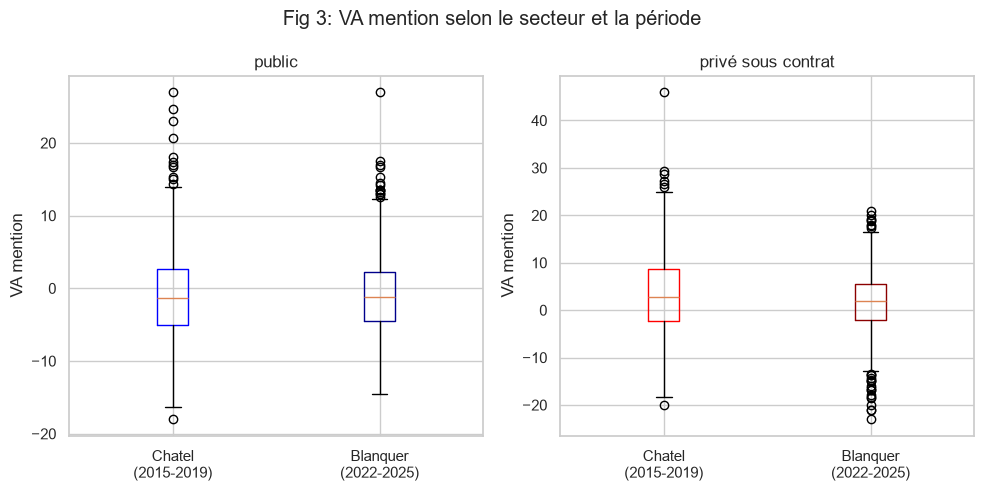

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, secteur, couleurs in [(axes[0], "public", ["blue", "darkblue"]), (axes[1], "privé sous contrat", ["red", "darkred"])]:
    bloc = apparies[apparies["secteur"] == secteur]
    boite = ax.boxplot([bloc["mention_c"], bloc["mention_b"]], tick_labels=["Chatel\n(2015-2019)", "Blanquer\n(2022-2025)"])
    boite["boxes"][0].set(color=couleurs[0])
    boite["boxes"][1].set(color=couleurs[1])
    ax.set_title(secteur)
    ax.set_ylabel("VA mention")

fig.suptitle("Fig 3: VA mention selon le secteur et la période")
plt.tight_layout()
plt.show()

## VI - Power analysis of the tests (bootstrap)

### VI.1 Power of the Mann-Whitney test (Q1)

In [21]:
nbr_simulation = 5000

tailles = [10, 20, 30, 50, 80, 100, 200, len(va_petits)]
puissance_q1 = []

for n in tailles:
    cpt = 0
    for i in range(nbr_simulation):
        s1 = np.random.choice(va_petits.values, size=n, replace=True)
        s2 = np.random.choice(va_grands.values, size=n, replace=True)
        W, p = stats.mannwhitneyu(s1, s2, alternative="two-sided")
        if p < 0.05:
            cpt += 1
    puissance = round(cpt / nbr_simulation * 100, 1)
    puissance_q1.append(puissance)
    print(f"n = {n}, puissance = {puissance}%")

n = 10, puissance = 16.3%
n = 20, puissance = 30.3%
n = 30, puissance = 42.6%
n = 50, puissance = 64.7%
n = 80, puissance = 84.4%
n = 100, puissance = 90.7%
n = 200, puissance = 99.8%
n = 1042, puissance = 100.0%


### VI.2 Power of the Wilcoxon signed-rank test (Q2)

In [22]:
diff = diff_mention[diff_mention != 0].values
tailles_q2 = [20, 50, 100, 200, 500, 1000, 1500, len(diff)]
puissance_q2 = []

for n in tailles_q2:
    cpt = 0
    for i in range(nbr_simulation):
        echantillon = np.random.choice(diff, size=n, replace=True)
        T, p = stats.wilcoxon(echantillon)
        if p < 0.05:
            cpt += 1
    puissance = round(cpt / nbr_simulation * 100, 1)
    puissance_q2.append(puissance)
    print(f"n = {n}, puissance = {puissance}%")

n = 20, puissance = 6.0%
n = 50, puissance = 7.2%
n = 100, puissance = 10.3%
n = 200, puissance = 16.3%
n = 500, puissance = 32.5%
n = 1000, puissance = 58.6%
n = 1500, puissance = 75.2%
n = 2270, puissance = 89.3%


### VI.3 Power curves

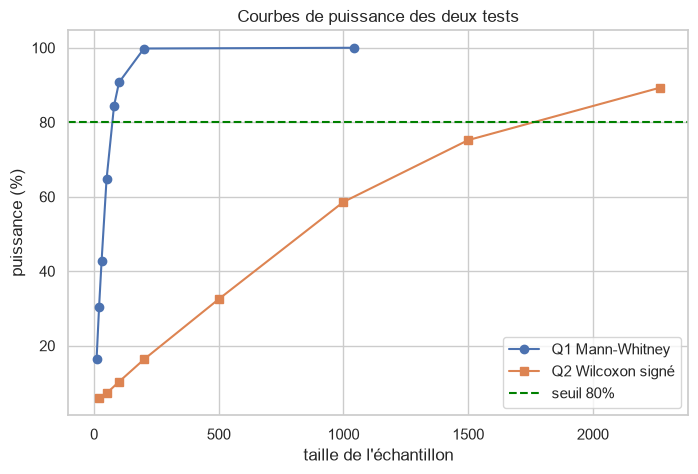

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(tailles, puissance_q1, "o-", label="Q1 Mann-Whitney")
plt.plot(tailles_q2, puissance_q2, "s-", label="Q2 Wilcoxon signé")
plt.axhline(y=80, color="green", linestyle="--", label="seuil 80%")
plt.xlabel("taille de l'échantillon")
plt.ylabel("puissance (%)")
plt.title("Courbes de puissance des deux tests")
plt.legend()
plt.show()